# Notebook 3 - CBAM-CNN Fine-tuning and Feature Extraction

**Per-backbone pipeline:**
1. `Input -> Augmentation -> preprocess_input -> Backbone (partial freeze) -> CBAM -> GAP -> Dropout -> Dense(N) -> Dropout -> Dense(3, softmax)`
2. Fine-tune: Adam lr=1e-4, max 20 epochs, EarlyStopping patience=6
3. Evaluate on test set, save model + curves + confusion matrix
4. Extract features from `feature_extractor` (GAP) layer
5. Save `.npy` arrays + results to `all_results.json`

**Prerequisite:** run `Build_Master_Zip.ipynb` once to create `Master_Dataset.zip`.

In [ ]:
# =============================================
# CELL 1: INSTALL DEPENDENCIES
# =============================================
!pip install -q tensorflow keras scikit-learn pandas matplotlib seaborn tqdm codecarbon
print("Dependencies installed.")

Dependencies installed.


In [ ]:
# =============================================
# CELL 2: MOUNT DRIVE + CHECK DRIVE-SIDE FILES
# =============================================
import os
from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

MASTER_CSV_DIR = f"{PROJECT_ROOT}/master_dataset"
ZIP_DRIVE      = f"{PROJECT_ROOT}/master_dataset.zip"

OUTPUT_DIR = f"{PROJECT_ROOT}/features"
MODELS_DIR = f"{PROJECT_ROOT}/models"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

import pandas as pd
for name in ["train_balanced.csv", "val.csv", "test.csv"]:
    p = os.path.join(MASTER_CSV_DIR, name)
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing CSV: {p}")
    df = pd.read_csv(p)
    print(f"{name:22s}: {len(df):>6,d} rows  |  classes: {df['label'].value_counts().sort_index().to_dict()}")

assert os.path.exists(ZIP_DRIVE), f"Master_Dataset.zip not found. Run Build_Master_Zip.ipynb first."
size_mb = os.path.getsize(ZIP_DRIVE) / (1024 * 1024)
print(f"\nMaster_Dataset.zip found ({size_mb:.1f} MB).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train_balanced.csv    : 36,000 rows  |  classes: {0: 12000, 1: 12000, 2: 12000}
val.csv               :  5,796 rows  |  classes: {0: 2715, 1: 1569, 2: 1512}
test.csv              :  5,528 rows  |  classes: {0: 2328, 1: 1428, 2: 1772}

Master_Dataset.zip found (327.6 MB).


In [ ]:
# =============================================
# CELL 2B: LOCAL CACHE FOR FASTER I/O (val/test from extracted_patches, train from balanced_train_only.zip)
# =============================================
# extracted_patches/{LUNA16,LIDC_IDRI,LNDb} live as plain (unzipped) folders on
# Drive, so val/test images are copied file-by-file (only the ~11k rows actually
# referenced by val.csv/test.csv, not the full ~37k patches, since train uses the
# balanced set instead). balanced_train_only.zip already exists on Drive as a
# single archive, so it is copied+unzipped in one shot (much faster for 36k files).

import os, shutil, subprocess, time
import pandas as pd
from tqdm.notebook import tqdm

ZIP2_DRIVE = f"{PROJECT_ROOT}/balanced_train_only.zip"
ZIP2_LOCAL = "/content/Balanced_Dataset_Train_Only.zip"

LOCAL_ROOT     = "/content/local_data"
LOCAL_CSVS     = "/content/local_csvs"
MASTER_CSV_DIR = f"{PROJECT_ROOT}/master_dataset"

os.makedirs(LOCAL_ROOT, exist_ok=True)
os.makedirs(LOCAL_CSVS, exist_ok=True)

# --- Step 1: TRAIN (balanced) — copy + unzip balanced_train_only.zip --------
already_extracted = (
    os.path.isdir(os.path.join(LOCAL_ROOT, "balanced_train_only", "class_0"))
    or os.path.isdir(os.path.join(LOCAL_ROOT, "class_0"))
)
if not already_extracted:
    print(f"Copying {ZIP2_DRIVE} ...")
    t0 = time.time()
    shutil.copy(ZIP2_DRIVE, ZIP2_LOCAL)
    print(f"   Copied ({os.path.getsize(ZIP2_LOCAL)/(1024*1024):.1f} MB) in {time.time()-t0:.1f}s")
    print("Unzipping ...")
    t0 = time.time()
    subprocess.run(['unzip', '-q', ZIP2_LOCAL, '-d', LOCAL_ROOT], check=True)
    os.remove(ZIP2_LOCAL)
    print(f"   Done in {time.time()-t0:.1f}s")
else:
    print("balanced_train_only already extracted locally (skipping).")

# Auto-detect whether the zip kept a wrapping "balanced_train_only/" folder or not
if os.path.isdir(os.path.join(LOCAL_ROOT, "balanced_train_only", "class_0")):
    BALANCED_LOCAL_ROOT = os.path.join(LOCAL_ROOT, "balanced_train_only")
elif os.path.isdir(os.path.join(LOCAL_ROOT, "class_0")):
    BALANCED_LOCAL_ROOT = LOCAL_ROOT
else:
    raise RuntimeError(
        "Could not locate class_0/ after unzipping balanced_train_only.zip — "
        "check its contents with `!unzip -l /content/Balanced_Dataset_Train_Only.zip | head`."
    )
print(f"Balanced train patches found at: {BALANCED_LOCAL_ROOT}")

# --- Step 2: VAL/TEST — copy only the files referenced in val.csv/test.csv --
def cache_split_locally(csv_name):
    df = pd.read_csv(os.path.join(MASTER_CSV_DIR, csv_name))
    new_paths, n_copied, n_skipped = [], 0, 0
    for p in tqdm(df['path'], desc=csv_name):
        idx = p.find("extracted_patches")
        if idx == -1:
            new_paths.append(p)  # unexpected path shape, leave untouched
            continue
        rel = p[idx:]  # e.g. "extracted_patches/LUNA16/class_0/xxx.png"
        dst = os.path.join(LOCAL_ROOT, rel)
        if not os.path.exists(dst):
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.copy(p, dst)
            n_copied += 1
        else:
            n_skipped += 1
        new_paths.append(dst)
    df['path'] = new_paths
    n_exist = df['path'].apply(os.path.exists).sum()
    status = "OK  " if n_exist == len(df) else "FAIL"
    print(f"   [{status}] {csv_name:22s}: {len(df):>6,d} rows | "
          f"copied={n_copied} skipped(existing)={n_skipped} | exist locally={n_exist}")
    if n_exist < len(df):
        print("      First 3 missing:")
        for p in df[~df['path'].apply(os.path.exists)]['path'].head(3).tolist():
            print(f"        {p}")
    df.to_csv(os.path.join(LOCAL_CSVS, csv_name), index=False)
    return df

print("\n=== Caching val/test locally (from extracted_patches on Drive) ===")
val_df  = cache_split_locally("val.csv")
test_df = cache_split_locally("test.csv")

# --- Step 3: TRAIN — rewrite train_balanced.csv paths against BALANCED_LOCAL_ROOT ---
print("\n=== Rewriting train_balanced.csv paths ===")
df_train = pd.read_csv(os.path.join(MASTER_CSV_DIR, "train_balanced.csv"))

def rewrite_train_path(p):
    idx = p.find("balanced_train_only")
    if idx == -1:
        return p
    rel = p[idx + len("balanced_train_only"):].lstrip("/")  # "class_0/xxx.png"
    return os.path.join(BALANCED_LOCAL_ROOT, rel)

df_train['path'] = df_train['path'].apply(rewrite_train_path)
n_exist = df_train['path'].apply(os.path.exists).sum()
status = "OK  " if n_exist == len(df_train) else "FAIL"
print(f"   [{status}] train_balanced.csv    : {len(df_train):>6,d} rows | exist locally: {n_exist:>6,d}")
if n_exist < len(df_train):
    print("      First 3 missing:")
    for p in df_train[~df_train['path'].apply(os.path.exists)]['path'].head(3).tolist():
        print(f"        {p}")
df_train.to_csv(os.path.join(LOCAL_CSVS, "train_balanced.csv"), index=False)

# --- Step 4: redirect global CSV variables -----------------------------------
TRAIN_CSV = os.path.join(LOCAL_CSVS, "train_balanced.csv")
VAL_CSV   = os.path.join(LOCAL_CSVS, "val.csv")
TEST_CSV  = os.path.join(LOCAL_CSVS, "test.csv")
print(f"\nTRAIN_CSV / VAL_CSV / TEST_CSV now point to {LOCAL_CSVS}")


In [ ]:
# =============================================
# CELL 3: IMPORTS + GPU + MIXED PRECISION
# =============================================
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from codecarbon import OfflineEmissionsTracker

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import (
    ResNet50V2, DenseNet201, EfficientNetB3, EfficientNetV2L
)
from tensorflow.keras.applications import resnet_v2, densenet, efficientnet
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
)
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')

gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs: {gpus}")
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

# Mixed precision: ~1.6x faster on T4, ~40% less VRAM.
# Final softmax forced to float32 for numerical stability.
tf.keras.mixed_precision.set_global_policy('mixed_float16')
print(f"Mixed precision policy: {tf.keras.mixed_precision.global_policy().name}")

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: mixed_float16


In [ ]:
# =============================================
# CELL 4: GLOBAL CONFIGURATION (Table I)
# =============================================
BACKBONE_CFG = {
    'ResNet50V2': {
        'img_size'         : 224,
        'batch_size'       : 32,
        'n_layers_unfreeze': 30,
        'preprocess_fn'    : resnet_v2.preprocess_input,
        'head_dense'       : 1024,
        'has_internal_prep': False,
    },
    'DenseNet201': {
        'img_size'         : 224,
        'batch_size'       : 32,
        'n_layers_unfreeze': 40,
        'preprocess_fn'    : densenet.preprocess_input,
        'head_dense'       : 1024,
        'has_internal_prep': False,
    },
    'EfficientNetB3': {
        'img_size'         : 224,
        'batch_size'       : 32,
        'n_layers_unfreeze': 50,
        'preprocess_fn'    : efficientnet.preprocess_input,
        'head_dense'       : 1024,
        'has_internal_prep': False,
    },
    'EfficientNetV2L': {
        'img_size'         : 300,
        'batch_size'       : 16,
        'n_layers_unfreeze': 80,      # only last 80 layers (was: half of 1032 = 516)
        'preprocess_fn'    : None,
        'head_dense'       : 1280,
        'has_internal_prep': True,
        'learning_rate'    : 5e-5,    # half the default lr for stability
    },
}

NUM_CLASSES   = 3
MAX_EPOCHS    = 20
LEARNING_RATE = 1e-4
RANDOM_SEED   = 42
CLASS_NAMES   = ['Non-Nodule', 'Benign', 'Malignant']

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Global configuration loaded.")

Global configuration loaded.


In [ ]:
# =============================================
# CELL 5: tf.data PIPELINE
# =============================================
def build_dataset(csv_path, img_size, batch_size, shuffle=False, cache=False):
    df = pd.read_csv(csv_path)
    if shuffle:
        # Shuffle the dataframe ONCE at load time (deterministic, seeded).
        # Handles class-sorted CSVs without needing a huge tf.data shuffle buffer.
        df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
    paths  = df['path'].values
    labels = df['label'].values.astype(np.int32)

    def load_image(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, [img_size, img_size], method='bilinear')
        img = tf.cast(img, tf.float32)
        label = tf.one_hot(label, NUM_CLASSES)
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if cache:
        ds = ds.cache()
    # NO tf.data.Dataset.shuffle() here — the dataframe-level shuffle above
    # is sufficient AND deterministic, ensuring predict() and label-iteration
    # return the same order (which fixes the classification_report bug).
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds, len(df)

_ds, _n = build_dataset(TRAIN_CSV, 224, 4)
for imgs, labs in _ds.take(1):
    print(f"Sanity check: shape={imgs.shape}, dtype={imgs.dtype}, "
          f"min={imgs.numpy().min():.1f}, max={imgs.numpy().max():.1f}")
    print(f"   sample label: {labs.numpy()[0]}")
del _ds, _n

Sanity check: shape=(4, 224, 224, 3), dtype=<dtype: 'float32'>, min=0.0, max=254.9
   sample label: [1. 0. 0.]


In [ ]:
# =============================================
# CELL 6: CBAM MODULE
# =============================================
class ChannelAttention(layers.Layer):
    def __init__(self, reduction_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        self.avg_pool = layers.GlobalAveragePooling2D(keepdims=True)
        self.max_pool = layers.GlobalMaxPooling2D(keepdims=True)
        self.fc1 = layers.Dense(max(1, channels // self.reduction_ratio),
                                activation='relu', use_bias=False,
                                kernel_initializer='he_normal')
        self.fc2 = layers.Dense(channels, use_bias=False,
                                kernel_initializer='he_normal')
        super().build(input_shape)

    def call(self, x):
        avg_out = self.fc2(self.fc1(self.avg_pool(x)))
        max_out = self.fc2(self.fc1(self.max_pool(x)))
        return x * tf.sigmoid(avg_out + max_out)


class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding='same',
                                  use_bias=False,
                                  kernel_initializer='glorot_uniform')
        super().build(input_shape)

    def call(self, x):
        avg_out = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_out = tf.reduce_max(x, axis=-1, keepdims=True)
        return x * tf.sigmoid(self.conv(tf.concat([avg_out, max_out], axis=-1)))


class CBAM(layers.Layer):
    def __init__(self, reduction_ratio=8, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.channel_att = ChannelAttention(reduction_ratio)
        self.spatial_att = SpatialAttention(kernel_size)

    def call(self, x):
        return self.spatial_att(self.channel_att(x))

print("CBAM module defined.")

CBAM module defined.


In [ ]:
# =============================================
# CELL 7: MODEL BUILDER (methodology-aligned) - FIXED
# =============================================
# Two critical fixes vs. previous version:
#   1. Cast to float32 before preprocess_input (mixed precision was passing
#      float16 to functions that expect float32, breaking the math).
#   2. Keep ALL BatchNorm layers in inference mode during fine-tuning.
#      This is the #1 cause of huge train-val gaps when partially fine-tuning
#      ResNet/DenseNet: the unfrozen BN layers drift their running stats
#      based on the new training distribution, breaking val/test inference.

def build_cbam_model(backbone_name):
    cfg = BACKBONE_CFG[backbone_name]
    img_size = cfg['img_size']

    inputs = keras.Input(shape=(img_size, img_size, 3), name='input_image')

    # --- Online augmentation (active only during training) -------------------
    x = layers.RandomFlip("horizontal", seed=RANDOM_SEED, name='aug_flip')(inputs)
    x = layers.RandomRotation(15.0/360.0, fill_mode='nearest',
                              seed=RANDOM_SEED, name='aug_rot')(x)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode='nearest',
                                 seed=RANDOM_SEED, name='aug_shift')(x)
    x = layers.RandomZoom(0.1, 0.1, fill_mode='nearest',
                          seed=RANDOM_SEED, name='aug_zoom')(x)

    # --- Preprocessing + backbone --------------------------------------------
    if cfg['has_internal_prep']:
        # EfficientNetV2L handles cast + preprocessing internally
        backbone = EfficientNetV2L(
            include_top=False, weights='imagenet',
            include_preprocessing=True, input_tensor=x,
        )
    else:
        # FIX 1: force float32 BEFORE preprocess_input
        x = layers.Lambda(lambda t: tf.cast(t, tf.float32),
                          name='to_fp32')(x)
        x = layers.Lambda(cfg['preprocess_fn'], name='preprocess')(x)
        backbone_cls = {
            'ResNet50V2'    : ResNet50V2,
            'DenseNet201'   : DenseNet201,
            'EfficientNetB3': EfficientNetB3,
        }[backbone_name]
        backbone = backbone_cls(
            include_top=False, weights='imagenet', input_tensor=x,
        )

    # --- Freeze strategy (Table I) -------------------------------------------
    backbone.trainable = True
    if cfg['n_layers_unfreeze'] is not None:
        for layer in backbone.layers[:-cfg['n_layers_unfreeze']]:
            layer.trainable = False
        n_trainable_layers = cfg['n_layers_unfreeze']
    else:
        cutoff = len(backbone.layers) // 2
        for layer in backbone.layers[:cutoff]:
            layer.trainable = False
        n_trainable_layers = len(backbone.layers) - cutoff

    # --- FIX 2: keep all BatchNorm layers in inference mode ------------------
    n_bn_frozen = 0
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
            n_bn_frozen += 1

    # --- CBAM + methodology head ---------------------------------------------
    feat = backbone.output
    feat = CBAM(reduction_ratio=8, kernel_size=7, name='cbam')(feat)
    feat = layers.GlobalAveragePooling2D(name='feature_extractor')(feat)
    feat = layers.Dropout(0.5, name='dropout_1')(feat)
    feat = layers.Dense(cfg['head_dense'], activation='relu',
                        name=f"dense_{cfg['head_dense']}")(feat)
    feat = layers.Dropout(0.5, name='dropout_2')(feat)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax',
                           dtype='float32', name='predictions')(feat)

    model = Model(inputs=inputs, outputs=outputs, name=f"CBAM_{backbone_name}")

    print(f"   Architecture          : CBAM_{backbone_name}")
    print(f"   Input                 : {img_size}x{img_size}x3")
    print(f"   Backbone layers       : {len(backbone.layers)} ({n_trainable_layers} unfrozen)")
    print(f"   BatchNorm frozen      : {n_bn_frozen} layers")
    print(f"   Total parameters      : {model.count_params():,}")
    print(f"   Trainable parameters  : {sum(np.prod(v.shape) for v in model.trainable_variables):,}")
    return model, backbone

print("build_cbam_model() defined (with float32-cast and BN freeze fixes).")

build_cbam_model() defined (with float32-cast and BN freeze fixes).


In [ ]:
# =============================================
# CELL 8: TRAINING FUNCTION (single phase)
# =============================================
def train_model(model, backbone_name, train_ds, val_ds):
    metrics = [
        'accuracy',
        keras.metrics.AUC(name='auc', multi_label=False),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
    # Use per-backbone learning rate if specified, else the global default.
    # Also add gradient clipping for stability with large models in mixed precision.
    cfg = BACKBONE_CFG[backbone_name]
    lr = cfg.get('learning_rate', LEARNING_RATE)
    print(f"   Optimizer: Adam(lr={lr}, clipnorm=1.0)")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0),
        loss='categorical_crossentropy',
        metrics=metrics,
    )

    ckpt_path = os.path.join(MODELS_DIR, f"CBAM_{backbone_name}_best.keras")
    log_path  = os.path.join(OUTPUT_DIR, f"{backbone_name}_training_log.csv")

    callbacks = [
        EarlyStopping(monitor='val_accuracy', patience=6,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3,
                          min_lr=1e-7, verbose=1),
        ModelCheckpoint(ckpt_path, monitor='val_accuracy',
                        save_best_only=True, verbose=1),
        CSVLogger(log_path, append=False),
    ]
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=MAX_EPOCHS, callbacks=callbacks, verbose=1,
    )
    return history, ckpt_path

    ckpt_path = os.path.join(MODELS_DIR, f"CBAM_{backbone_name}_best.keras")
    log_path  = os.path.join(OUTPUT_DIR, f"{backbone_name}_training_log.csv")

    callbacks = [
        EarlyStopping(monitor='val_accuracy', patience=6,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3,
                          min_lr=1e-7, verbose=1),
        ModelCheckpoint(ckpt_path, monitor='val_accuracy',
                        save_best_only=True, verbose=1),
        CSVLogger(log_path, append=False),
    ]
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=MAX_EPOCHS, callbacks=callbacks, verbose=1,
    )
    return history, ckpt_path

print("train_model() defined.")

train_model() defined.


In [ ]:
# =============================================
# CELL 9: FEATURE EXTRACTION
# =============================================
def build_feature_extractor(model):
    return Model(
        inputs=model.input,
        outputs=model.get_layer('feature_extractor').output,
        name=f"{model.name}_features"
    )


def extract_features(feature_extractor, dataset, n_samples, batch_size, desc=""):
    all_features, all_labels = [], []
    total = (n_samples + batch_size - 1) // batch_size
    for images, labels in tqdm(dataset, desc=desc, total=total):
        feats = feature_extractor(images, training=False).numpy()
        all_features.append(feats)
        all_labels.append(np.argmax(labels.numpy(), axis=1))
    X = np.concatenate(all_features, axis=0)
    y = np.concatenate(all_labels,  axis=0)
    return X.astype(np.float32), y.astype(np.int32)

print("Feature extraction functions defined.")

Feature extraction functions defined.


In [ ]:
# =============================================
# CELL 10: VISUALIZATIONS
# =============================================
def plot_training_curves(history, backbone_name):
    h = history.history
    epochs = range(1, len(h['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, key, ylabel in [(axes[0], 'accuracy', 'Accuracy'),
                            (axes[1], 'loss',     'Loss')]:
        ax.plot(epochs, h[key],          'b-o', label='Train', markersize=4)
        ax.plot(epochs, h[f'val_{key}'], 'r-o', label='Val',   markersize=4)
        ax.set_title(f'{backbone_name} - {ylabel}', fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
        ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    out = os.path.join(OUTPUT_DIR, f"{backbone_name}_curves.png")
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {out}")


def plot_confusion(y_true, y_pred, backbone_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{backbone_name} - Confusion Matrix (Test)', fontweight='bold')
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.tight_layout()
    out = os.path.join(OUTPUT_DIR, f"{backbone_name}_confusion.png")
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {out}")

print("Visualization functions defined.")

Visualization functions defined.


New results file.

CBAM + ResNet50V2  |  224x224  |  batch=32

Loading datasets...
   Train: 36000  |  Val: 5796  |  Test: 5528
   First train batch class distribution: {np.int64(0): np.int64(15), np.int64(1): np.int64(11), np.int64(2): np.int64(6)}
   Val determinism check: OK (160 labels match across two passes)

Building model...
   Architecture          : CBAM_ResNet50V2
   Input                 : 224x224x3
   Backbone layers       : 196 (30 unfrozen)
   BatchNorm frozen      : 49 layers
   Total parameters      : 26,714,725
   Trainable parameters  : 17,576,037

Fine-tuning (20 epochs max, EarlyStopping patience=6)...
Epoch 1/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.6446 - auc: 0.8210 - loss: 0.7747 - precision: 0.7201 - recall: 0.5123
Epoch 1: val_accuracy improved from None to 0.81297, saving model to /content/drive/MyDrive/Journal_Work_2026/Models_v2/CBAM_ResNet50V2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Journal_Work_2026/Model

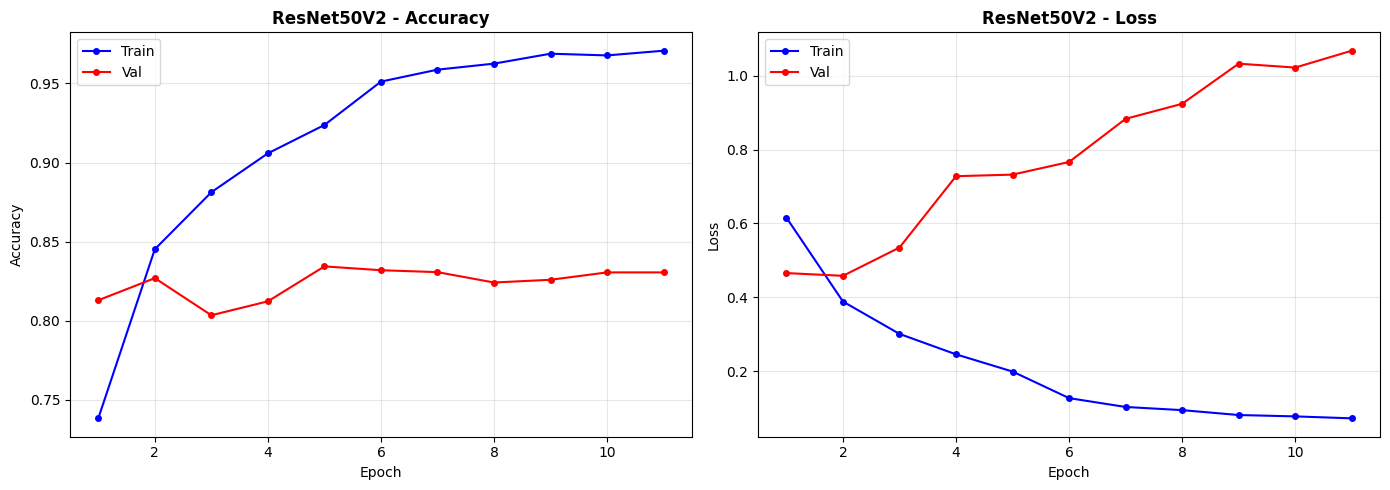

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/ResNet50V2_curves.png

173/173 ━━━━━━━━━━━━━━━━━━━━ 24s 127ms/step
   Manual acc (y_pred vs y_true): 0.8191
   model.evaluate accuracy      : 0.8191
   OK: accuracies match - reports below are trustworthy.


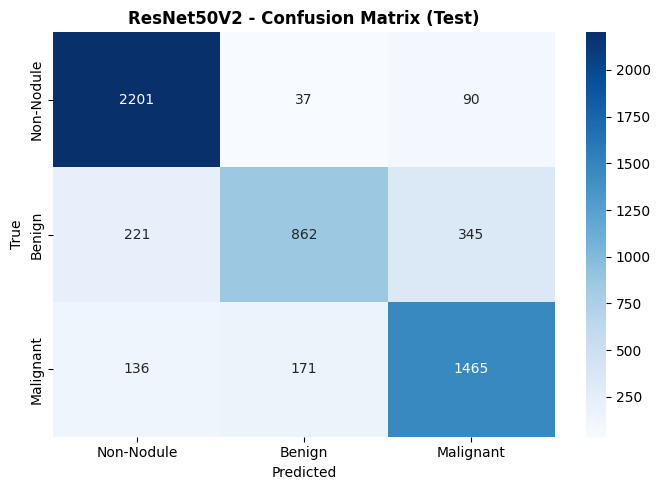

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/ResNet50V2_confusion.png

Classification Report (Test):
              precision    recall  f1-score   support

  Non-Nodule     0.8604    0.9454    0.9009      2328
      Benign     0.8056    0.6036    0.6902      1428
   Malignant     0.7711    0.8267    0.7979      1772

    accuracy                         0.8191      5528
   macro avg     0.8124    0.7919    0.7963      5528
weighted avg     0.8176    0.8191    0.8135      5528


Extracting features from 'feature_extractor' layer...
   Embedding dimension: 2048


Train ResNet50V2:   0%|          | 0/1125 [00:00<?, ?it/s]

Val   ResNet50V2:   0%|          | 0/182 [00:00<?, ?it/s]

Test  ResNet50V2:   0%|          | 0/173 [00:00<?, ?it/s]

   Shapes: train=(36000, 2048), val=(5796, 2048), test=(5528, 2048)
   Features saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/ResNet50V2
   Model saved   : CBAM_ResNet50V2_final.keras

ResNet50V2 - DONE
   Test Accuracy : 81.91%
   Test AUC      : 0.9280
   Macro F1      : 0.7963
   Test Loss     : 0.7484
   Duration      : 40.5 min
   Backbones done: ['ResNet50V2']

Next: change CURRENT_ARCH at top of this cell and re-run.


In [ ]:
# =============================================
# CELL 11: MAIN LOOP - ONE BACKBONE PER RUN
# =============================================
# Change CURRENT_ARCH and re-run only this cell to train the next backbone.
# Already-trained backbones are skipped automatically.

CURRENT_ARCH = 'ResNet50V2'
# CURRENT_ARCH = 'DenseNet201'
# CURRENT_ARCH = 'EfficientNetB3'
# CURRENT_ARCH = 'EfficientNetV2L'

results_path = os.path.join(OUTPUT_DIR, 'all_results.json')
if os.path.exists(results_path):
    with open(results_path) as f:
        all_results = json.load(f)
    print(f"Existing results: {list(all_results.keys())}")
else:
    all_results = {}
    print("New results file.")

if CURRENT_ARCH in all_results:
    acc = all_results[CURRENT_ARCH]['test_accuracy']*100
    print(f"{CURRENT_ARCH} already trained (acc={acc:.2f}%) - skipping.")
else:
    cfg = BACKBONE_CFG[CURRENT_ARCH]
    print("\n" + "="*70)
    print(f"CBAM + {CURRENT_ARCH}  |  {cfg['img_size']}x{cfg['img_size']}  |  batch={cfg['batch_size']}")
    print("="*70)

    # --- Datasets ------------------------------------------------------------
    print("\nLoading datasets...")
    train_ds, n_train = build_dataset(TRAIN_CSV, cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=False)
    # Re-shuffle train ONLY at each epoch, on top of the already-mixed CSV.
    # Buffer of 1024 is plenty since the CSV is no longer class-sorted.
    train_ds = train_ds.shuffle(buffer_size=1024, seed=RANDOM_SEED,
                                reshuffle_each_iteration=True)
    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

    # Val and test: deterministic single shuffle at load time (no per-epoch reshuffle).
    # shuffle=True here triggers df.sample() inside build_dataset; the tf.data
    # pipeline keeps the order fixed so predict() and label-iteration align.
    val_ds,   n_val   = build_dataset(VAL_CSV,   cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    test_ds,  n_test  = build_dataset(TEST_CSV,  cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    print(f"   Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

    # --- Sanity checks (catch bugs in 5 seconds before 48 min of training) ---
    for imgs, labs in train_ds.take(1):
        t = np.argmax(labs.numpy(), axis=1)
        unique_counts = dict(zip(*np.unique(t, return_counts=True)))
        print(f"   First train batch class distribution: {unique_counts}")
        assert len(unique_counts) >= 2, "Train batch contains only ONE class - shuffle is broken!"

    val_labels_pass1 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    val_labels_pass2 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    assert np.array_equal(val_labels_pass1, val_labels_pass2), \
        "Val dataset is non-deterministic between passes - predict/labels misalignment!"
    print(f"   Val determinism check: OK ({len(val_labels_pass1)} labels match across two passes)")

    # --- Model ---------------------------------------------------------------
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED)
    print("\nBuilding model...")
    model, backbone = build_cbam_model(CURRENT_ARCH)

    # --- Training + CodeCarbon -----------------------------------------------
    tracker = OfflineEmissionsTracker(
        project_name=f"CBAM_{CURRENT_ARCH}_v2",
        output_dir=OUTPUT_DIR,
        output_file=f"{CURRENT_ARCH}_emissions.csv",
        country_iso_code="MAR",
        log_level="error",
    )
    tracker.start()
    t0 = time.time()

    print(f"\nFine-tuning ({MAX_EPOCHS} epochs max, EarlyStopping patience=6)...")
    history, ckpt_path = train_model(model, CURRENT_ARCH, train_ds, val_ds)

    # --- Test evaluation -----------------------------------------------------
    print(f"\nEvaluating on the Test Set...")
    test_results = model.evaluate(test_ds, verbose=1, return_dict=True)
    print(f"   Test metrics: {test_results}")

    duration_s   = time.time() - t0
    emissions_kg = tracker.stop()
    print(f"   Duration : {duration_s/60:.1f} min")
    print(f"   CO2eq    : {float(emissions_kg)*1000:.2f} g")

    # --- Predictions and consistency check -----------------------------------
    plot_training_curves(history, CURRENT_ARCH)

    print("\nCollecting predictions on test set...")
    y_pred_proba = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.concatenate([np.argmax(labs.numpy(), axis=1) for _, labs in test_ds])

    # CRITICAL sanity check: manual accuracy must match model.evaluate accuracy
    manual_acc = (y_pred == y_true).mean()
    print(f"   Manual acc (y_pred vs y_true): {manual_acc:.4f}")
    print(f"   model.evaluate accuracy      : {test_results['accuracy']:.4f}")
    if abs(manual_acc - test_results['accuracy']) > 0.01:
        print("   WARNING: accuracies disagree - data pipeline ordering bug!")
    else:
        print("   OK: accuracies match - reports below are trustworthy.")

    plot_confusion(y_true, y_pred, CURRENT_ARCH)

    print("\nClassification Report (Test):")
    report_str  = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
    report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                        output_dict=True)
    print(report_str)

    # --- Feature extraction --------------------------------------------------
    print(f"\nExtracting features from 'feature_extractor' layer...")
    feat_extractor = build_feature_extractor(model)
    print(f"   Embedding dimension: {feat_extractor.output_shape[-1]}")

    X_train, y_train = extract_features(feat_extractor, train_ds, n_train,
                                        cfg['batch_size'], f"Train {CURRENT_ARCH}")
    X_val,   y_val   = extract_features(feat_extractor, val_ds,   n_val,
                                        cfg['batch_size'], f"Val   {CURRENT_ARCH}")
    X_test,  y_test  = extract_features(feat_extractor, test_ds,  n_test,
                                        cfg['batch_size'], f"Test  {CURRENT_ARCH}")
    print(f"   Shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")

    # --- Save ---------------------------------------------------------------
    feat_dir = os.path.join(OUTPUT_DIR, CURRENT_ARCH)
    os.makedirs(feat_dir, exist_ok=True)
    np.save(os.path.join(feat_dir, 'X_train.npy'), X_train)
    np.save(os.path.join(feat_dir, 'y_train.npy'), y_train)
    np.save(os.path.join(feat_dir, 'X_val.npy'),   X_val)
    np.save(os.path.join(feat_dir, 'y_val.npy'),   y_val)
    np.save(os.path.join(feat_dir, 'X_test.npy'),  X_test)
    np.save(os.path.join(feat_dir, 'y_test.npy'),  y_test)
    print(f"   Features saved: {feat_dir}")

    model.save(os.path.join(MODELS_DIR, f"CBAM_{CURRENT_ARCH}_final.keras"))
    print(f"   Model saved   : CBAM_{CURRENT_ARCH}_final.keras")

    # --- Update results JSON -------------------------------------------------
    all_results[CURRENT_ARCH] = {
        'img_size'       : cfg['img_size'],
        'batch_size'     : cfg['batch_size'],
        'feature_dim'    : int(X_train.shape[1]),
        'epochs_trained' : len(history.history['loss']),
        'test_accuracy'  : float(test_results['accuracy']),
        'test_auc'       : float(test_results['auc']),
        'test_precision' : float(test_results['precision']),
        'test_recall'    : float(test_results['recall']),
        'test_loss'      : float(test_results['loss']),
        'macro_f1'       : float(report_dict['macro avg']['f1-score']),
        'weighted_f1'    : float(report_dict['weighted avg']['f1-score']),
        'per_class_f1'   : {CLASS_NAMES[i]: float(report_dict[CLASS_NAMES[i]]['f1-score'])
                            for i in range(NUM_CLASSES)},
        'carbon': {
            'duration_min': round(duration_s/60, 2),
            'co2_g'       : round(float(emissions_kg)*1000, 2),
            'energy_kwh'  : round(float(emissions_kg)/0.634, 4),
            'tracker'     : 'codecarbon_OfflineTracker_MAR',
        },
    }
    with open(results_path, 'w') as f:
        json.dump(all_results, f, indent=2)

    print("\n" + "="*70)
    print(f"{CURRENT_ARCH} - DONE")
    print(f"   Test Accuracy : {test_results['accuracy']*100:.2f}%")
    print(f"   Test AUC      : {test_results['auc']:.4f}")
    print(f"   Macro F1      : {report_dict['macro avg']['f1-score']:.4f}")
    print(f"   Test Loss     : {test_results['loss']:.4f}")
    print(f"   Duration      : {duration_s/60:.1f} min")
    print(f"   Backbones done: {list(all_results.keys())}")
    print("="*70)
    print("\nNext: change CURRENT_ARCH at top of this cell and re-run.")

Existing results: ['ResNet50V2']

CBAM + DenseNet201  |  224x224  |  batch=32

Loading datasets...
   Train: 36000  |  Val: 5796  |  Test: 5528
   First train batch class distribution: {np.int64(0): np.int64(15), np.int64(1): np.int64(11), np.int64(2): np.int64(6)}
   Val determinism check: OK (160 labels match across two passes)

Building model...
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
   Architecture          : CBAM_DenseNet201
   Input                 : 224x224x3
   Backbone layers       : 713 (40 unfrozen)
   BatchNorm frozen      : 201 layers
   Total parameters      : 21,213,861
   Trainable parameters  : 4,280,421

Fine-tuning (20 epochs max, EarlyStopping patience=6)...
Epoch 1/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - accuracy: 0.5531 - auc: 0.7408 - loss: 0.9222 - precision: 0.6180 - recall: 0.4083
Epoch 1: val_accuracy improved from None to 0.76639, saving model to /content/drive/MyDrive/Journal_Work_2026/Models_v2/CBAM_DenseNet201_best.keras

Epoch 1: fi

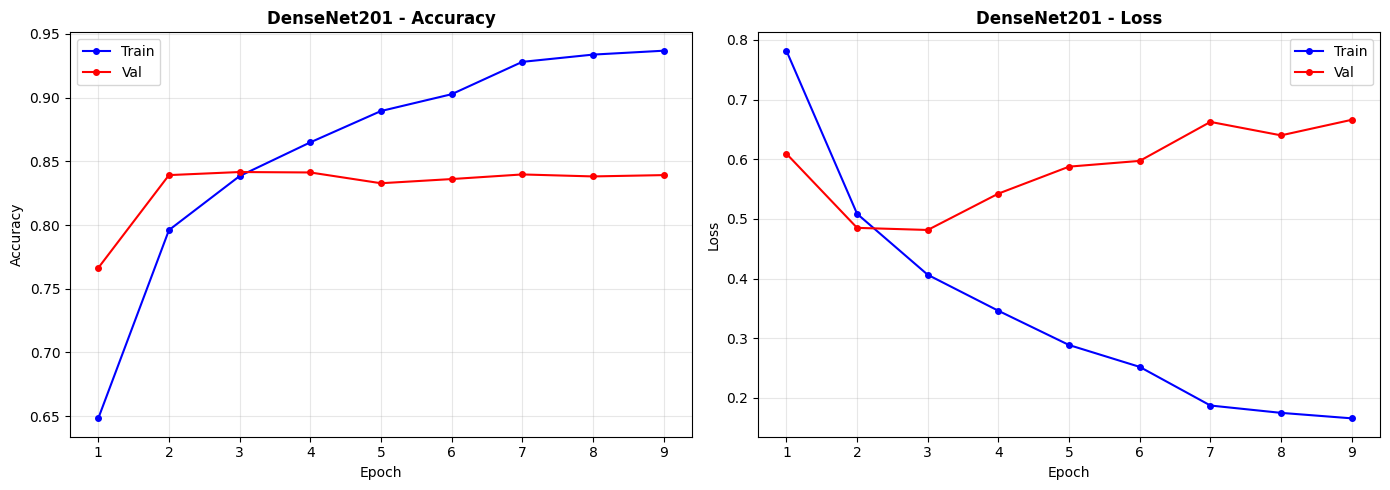

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/DenseNet201_curves.png

173/173 ━━━━━━━━━━━━━━━━━━━━ 53s 266ms/step
   Manual acc (y_pred vs y_true): 0.8345
   model.evaluate accuracy      : 0.8345
   OK: accuracies match - reports below are trustworthy.


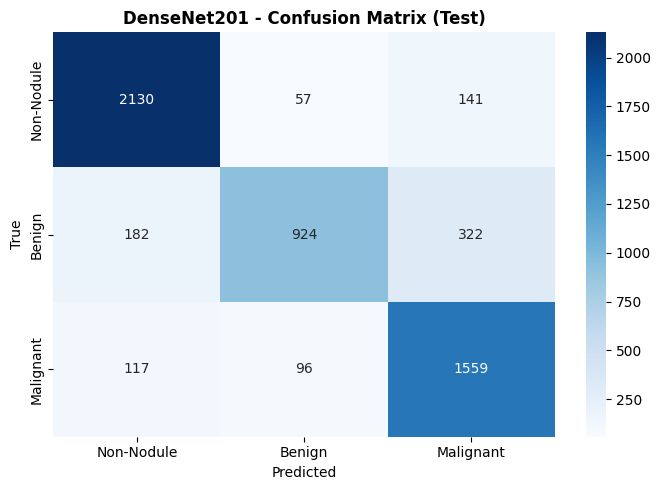

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/DenseNet201_confusion.png

Classification Report (Test):
              precision    recall  f1-score   support

  Non-Nodule     0.8769    0.9149    0.8955      2328
      Benign     0.8579    0.6471    0.7377      1428
   Malignant     0.7710    0.8798    0.8218      1772

    accuracy                         0.8345      5528
   macro avg     0.8353    0.8139    0.8184      5528
weighted avg     0.8381    0.8345    0.8311      5528


Extracting features from 'feature_extractor' layer...
   Embedding dimension: 1920


Train DenseNet201:   0%|          | 0/1125 [00:00<?, ?it/s]

Val   DenseNet201:   0%|          | 0/182 [00:00<?, ?it/s]

Test  DenseNet201:   0%|          | 0/173 [00:00<?, ?it/s]

   Shapes: train=(36000, 1920), val=(5796, 1920), test=(5528, 1920)
   Features saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/DenseNet201
   Model saved   : CBAM_DenseNet201_final.keras

DenseNet201 - DONE
   Test Accuracy : 83.45%
   Test AUC      : 0.9421
   Macro F1      : 0.8184
   Test Loss     : 0.4681
   Duration      : 51.5 min
   Backbones done: ['ResNet50V2', 'DenseNet201']

Next: change CURRENT_ARCH at top of this cell and re-run.


In [ ]:
# =============================================
# CELL 11: MAIN LOOP - ONE BACKBONE PER RUN
# =============================================
# Change CURRENT_ARCH and re-run only this cell to train the next backbone.
# Already-trained backbones are skipped automatically.

# CURRENT_ARCH = 'ResNet50V2'
CURRENT_ARCH = 'DenseNet201'
# CURRENT_ARCH = 'EfficientNetB3'
# CURRENT_ARCH = 'EfficientNetV2L'

results_path = os.path.join(OUTPUT_DIR, 'all_results.json')
if os.path.exists(results_path):
    with open(results_path) as f:
        all_results = json.load(f)
    print(f"Existing results: {list(all_results.keys())}")
else:
    all_results = {}
    print("New results file.")

if CURRENT_ARCH in all_results:
    acc = all_results[CURRENT_ARCH]['test_accuracy']*100
    print(f"{CURRENT_ARCH} already trained (acc={acc:.2f}%) - skipping.")
else:
    cfg = BACKBONE_CFG[CURRENT_ARCH]
    print("\n" + "="*70)
    print(f"CBAM + {CURRENT_ARCH}  |  {cfg['img_size']}x{cfg['img_size']}  |  batch={cfg['batch_size']}")
    print("="*70)

    # --- Datasets ------------------------------------------------------------
    print("\nLoading datasets...")
    train_ds, n_train = build_dataset(TRAIN_CSV, cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=False)
    # Re-shuffle train ONLY at each epoch, on top of the already-mixed CSV.
    # Buffer of 1024 is plenty since the CSV is no longer class-sorted.
    train_ds = train_ds.shuffle(buffer_size=1024, seed=RANDOM_SEED,
                                reshuffle_each_iteration=True)
    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

    # Val and test: deterministic single shuffle at load time (no per-epoch reshuffle).
    # shuffle=True here triggers df.sample() inside build_dataset; the tf.data
    # pipeline keeps the order fixed so predict() and label-iteration align.
    val_ds,   n_val   = build_dataset(VAL_CSV,   cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    test_ds,  n_test  = build_dataset(TEST_CSV,  cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    print(f"   Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

    # --- Sanity checks (catch bugs in 5 seconds before 48 min of training) ---
    for imgs, labs in train_ds.take(1):
        t = np.argmax(labs.numpy(), axis=1)
        unique_counts = dict(zip(*np.unique(t, return_counts=True)))
        print(f"   First train batch class distribution: {unique_counts}")
        assert len(unique_counts) >= 2, "Train batch contains only ONE class - shuffle is broken!"

    val_labels_pass1 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    val_labels_pass2 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    assert np.array_equal(val_labels_pass1, val_labels_pass2), \
        "Val dataset is non-deterministic between passes - predict/labels misalignment!"
    print(f"   Val determinism check: OK ({len(val_labels_pass1)} labels match across two passes)")

    # --- Model ---------------------------------------------------------------
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED)
    print("\nBuilding model...")
    model, backbone = build_cbam_model(CURRENT_ARCH)

    # --- Training + CodeCarbon -----------------------------------------------
    tracker = OfflineEmissionsTracker(
        project_name=f"CBAM_{CURRENT_ARCH}_v2",
        output_dir=OUTPUT_DIR,
        output_file=f"{CURRENT_ARCH}_emissions.csv",
        country_iso_code="MAR",
        log_level="error",
    )
    tracker.start()
    t0 = time.time()

    print(f"\nFine-tuning ({MAX_EPOCHS} epochs max, EarlyStopping patience=6)...")
    history, ckpt_path = train_model(model, CURRENT_ARCH, train_ds, val_ds)

    # --- Test evaluation -----------------------------------------------------
    print(f"\nEvaluating on the Test Set...")
    test_results = model.evaluate(test_ds, verbose=1, return_dict=True)
    print(f"   Test metrics: {test_results}")

    duration_s   = time.time() - t0
    emissions_kg = tracker.stop()
    print(f"   Duration : {duration_s/60:.1f} min")
    print(f"   CO2eq    : {float(emissions_kg)*1000:.2f} g")

    # --- Predictions and consistency check -----------------------------------
    plot_training_curves(history, CURRENT_ARCH)

    print("\nCollecting predictions on test set...")
    y_pred_proba = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.concatenate([np.argmax(labs.numpy(), axis=1) for _, labs in test_ds])

    # CRITICAL sanity check: manual accuracy must match model.evaluate accuracy
    manual_acc = (y_pred == y_true).mean()
    print(f"   Manual acc (y_pred vs y_true): {manual_acc:.4f}")
    print(f"   model.evaluate accuracy      : {test_results['accuracy']:.4f}")
    if abs(manual_acc - test_results['accuracy']) > 0.01:
        print("   WARNING: accuracies disagree - data pipeline ordering bug!")
    else:
        print("   OK: accuracies match - reports below are trustworthy.")

    plot_confusion(y_true, y_pred, CURRENT_ARCH)

    print("\nClassification Report (Test):")
    report_str  = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
    report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                        output_dict=True)
    print(report_str)

    # --- Feature extraction --------------------------------------------------
    print(f"\nExtracting features from 'feature_extractor' layer...")
    feat_extractor = build_feature_extractor(model)
    print(f"   Embedding dimension: {feat_extractor.output_shape[-1]}")

    X_train, y_train = extract_features(feat_extractor, train_ds, n_train,
                                        cfg['batch_size'], f"Train {CURRENT_ARCH}")
    X_val,   y_val   = extract_features(feat_extractor, val_ds,   n_val,
                                        cfg['batch_size'], f"Val   {CURRENT_ARCH}")
    X_test,  y_test  = extract_features(feat_extractor, test_ds,  n_test,
                                        cfg['batch_size'], f"Test  {CURRENT_ARCH}")
    print(f"   Shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")

    # --- Save ---------------------------------------------------------------
    feat_dir = os.path.join(OUTPUT_DIR, CURRENT_ARCH)
    os.makedirs(feat_dir, exist_ok=True)
    np.save(os.path.join(feat_dir, 'X_train.npy'), X_train)
    np.save(os.path.join(feat_dir, 'y_train.npy'), y_train)
    np.save(os.path.join(feat_dir, 'X_val.npy'),   X_val)
    np.save(os.path.join(feat_dir, 'y_val.npy'),   y_val)
    np.save(os.path.join(feat_dir, 'X_test.npy'),  X_test)
    np.save(os.path.join(feat_dir, 'y_test.npy'),  y_test)
    print(f"   Features saved: {feat_dir}")

    model.save(os.path.join(MODELS_DIR, f"CBAM_{CURRENT_ARCH}_final.keras"))
    print(f"   Model saved   : CBAM_{CURRENT_ARCH}_final.keras")

    # --- Update results JSON -------------------------------------------------
    all_results[CURRENT_ARCH] = {
        'img_size'       : cfg['img_size'],
        'batch_size'     : cfg['batch_size'],
        'feature_dim'    : int(X_train.shape[1]),
        'epochs_trained' : len(history.history['loss']),
        'test_accuracy'  : float(test_results['accuracy']),
        'test_auc'       : float(test_results['auc']),
        'test_precision' : float(test_results['precision']),
        'test_recall'    : float(test_results['recall']),
        'test_loss'      : float(test_results['loss']),
        'macro_f1'       : float(report_dict['macro avg']['f1-score']),
        'weighted_f1'    : float(report_dict['weighted avg']['f1-score']),
        'per_class_f1'   : {CLASS_NAMES[i]: float(report_dict[CLASS_NAMES[i]]['f1-score'])
                            for i in range(NUM_CLASSES)},
        'carbon': {
            'duration_min': round(duration_s/60, 2),
            'co2_g'       : round(float(emissions_kg)*1000, 2),
            'energy_kwh'  : round(float(emissions_kg)/0.634, 4),
            'tracker'     : 'codecarbon_OfflineTracker_MAR',
        },
    }
    with open(results_path, 'w') as f:
        json.dump(all_results, f, indent=2)

    print("\n" + "="*70)
    print(f"{CURRENT_ARCH} - DONE")
    print(f"   Test Accuracy : {test_results['accuracy']*100:.2f}%")
    print(f"   Test AUC      : {test_results['auc']:.4f}")
    print(f"   Macro F1      : {report_dict['macro avg']['f1-score']:.4f}")
    print(f"   Test Loss     : {test_results['loss']:.4f}")
    print(f"   Duration      : {duration_s/60:.1f} min")
    print(f"   Backbones done: {list(all_results.keys())}")
    print("="*70)
    print("\nNext: change CURRENT_ARCH at top of this cell and re-run.")

Existing results: ['ResNet50V2', 'DenseNet201']

CBAM + EfficientNetB3  |  224x224  |  batch=32

Loading datasets...
   Train: 36000  |  Val: 5796  |  Test: 5528
   First train batch class distribution: {np.int64(0): np.int64(15), np.int64(1): np.int64(11), np.int64(2): np.int64(6)}
   Val determinism check: OK (160 labels match across two passes)

Building model...
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
   Architecture          : CBAM_EfficientNetB3
   Input                 : 224x224x3
   Backbone layers       : 391 (50 unfrozen)
   BatchNorm frozen      : 78 layers
   Total parameters      : 12,950,420
   Trainable parameters  : 7,191,161

Fine-tuning (20 epochs max, EarlyStopping patience=6)...
Epoch 1/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.6284 - auc: 0.8079 - loss: 0.7991 - precision: 0.7111 - recall: 0.4715
Epoch 1: val_accuracy improved from None to 0.80090, saving model to /content/drive/MyDrive/Journal_Work_2026/Models_v2/CBAM_EfficientNetB3_

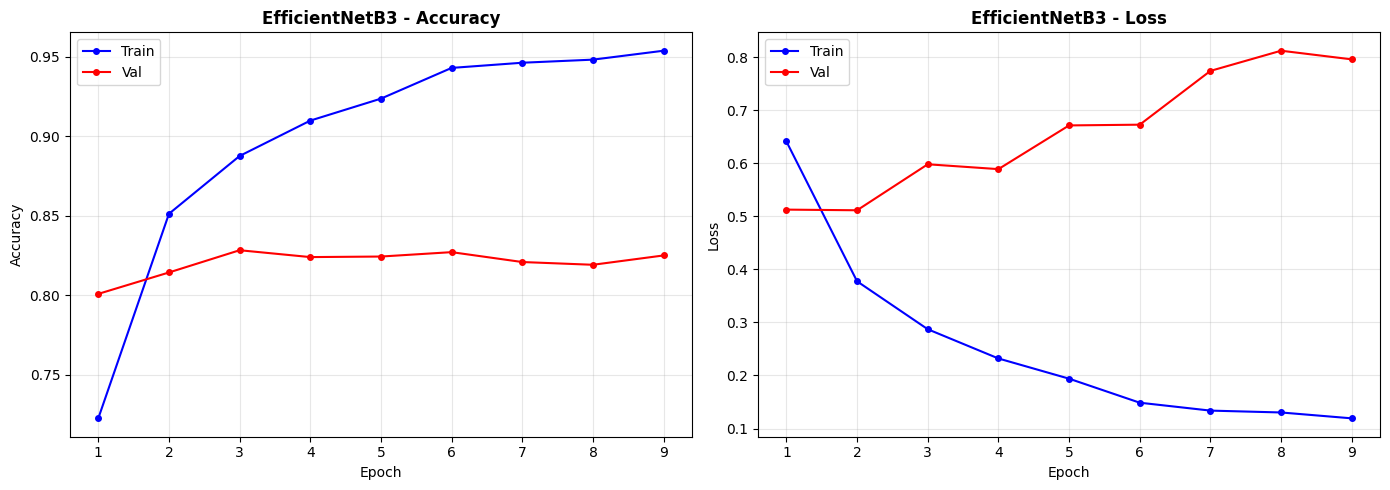

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetB3_curves.png

173/173 ━━━━━━━━━━━━━━━━━━━━ 31s 161ms/step
   Manual acc (y_pred vs y_true): 0.8180
   model.evaluate accuracy      : 0.8180
   OK: accuracies match - reports below are trustworthy.


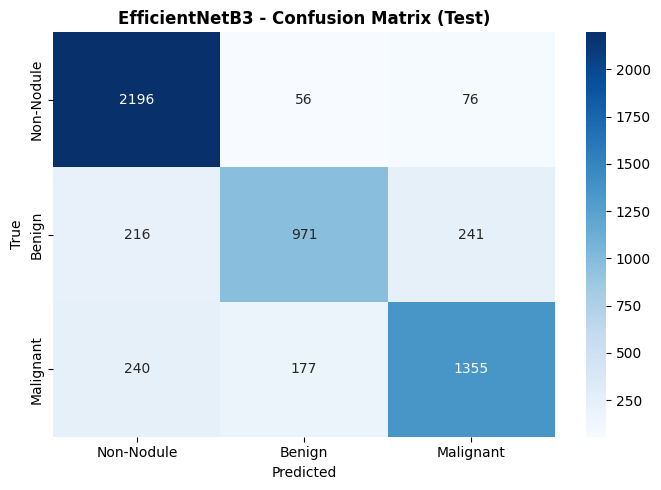

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetB3_confusion.png

Classification Report (Test):
              precision    recall  f1-score   support

  Non-Nodule     0.8281    0.9433    0.8819      2328
      Benign     0.8065    0.6800    0.7378      1428
   Malignant     0.8104    0.7647    0.7869      1772

    accuracy                         0.8180      5528
   macro avg     0.8150    0.7960    0.8022      5528
weighted avg     0.8168    0.8180    0.8142      5528


Extracting features from 'feature_extractor' layer...
   Embedding dimension: 1536


Train EfficientNetB3:   0%|          | 0/1125 [00:00<?, ?it/s]

Val   EfficientNetB3:   0%|          | 0/182 [00:00<?, ?it/s]

Test  EfficientNetB3:   0%|          | 0/173 [00:00<?, ?it/s]

   Shapes: train=(36000, 1536), val=(5796, 1536), test=(5528, 1536)
   Features saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetB3
   Model saved   : CBAM_EfficientNetB3_final.keras

EfficientNetB3 - DONE
   Test Accuracy : 81.80%
   Test AUC      : 0.9372
   Macro F1      : 0.8022
   Test Loss     : 0.5996
   Duration      : 34.6 min
   Backbones done: ['ResNet50V2', 'DenseNet201', 'EfficientNetB3']

Next: change CURRENT_ARCH at top of this cell and re-run.


In [ ]:
# =============================================
# CELL 11: MAIN LOOP - ONE BACKBONE PER RUN
# =============================================
# Change CURRENT_ARCH and re-run only this cell to train the next backbone.
# Already-trained backbones are skipped automatically.

# CURRENT_ARCH = 'ResNet50V2'
# CURRENT_ARCH = 'DenseNet201'
CURRENT_ARCH = 'EfficientNetB3'
# CURRENT_ARCH = 'EfficientNetV2L'

results_path = os.path.join(OUTPUT_DIR, 'all_results.json')
if os.path.exists(results_path):
    with open(results_path) as f:
        all_results = json.load(f)
    print(f"Existing results: {list(all_results.keys())}")
else:
    all_results = {}
    print("New results file.")

if CURRENT_ARCH in all_results:
    acc = all_results[CURRENT_ARCH]['test_accuracy']*100
    print(f"{CURRENT_ARCH} already trained (acc={acc:.2f}%) - skipping.")
else:
    cfg = BACKBONE_CFG[CURRENT_ARCH]
    print("\n" + "="*70)
    print(f"CBAM + {CURRENT_ARCH}  |  {cfg['img_size']}x{cfg['img_size']}  |  batch={cfg['batch_size']}")
    print("="*70)

    # --- Datasets ------------------------------------------------------------
    print("\nLoading datasets...")
    train_ds, n_train = build_dataset(TRAIN_CSV, cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=False)
    # Re-shuffle train ONLY at each epoch, on top of the already-mixed CSV.
    # Buffer of 1024 is plenty since the CSV is no longer class-sorted.
    train_ds = train_ds.shuffle(buffer_size=1024, seed=RANDOM_SEED,
                                reshuffle_each_iteration=True)
    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

    # Val and test: deterministic single shuffle at load time (no per-epoch reshuffle).
    # shuffle=True here triggers df.sample() inside build_dataset; the tf.data
    # pipeline keeps the order fixed so predict() and label-iteration align.
    val_ds,   n_val   = build_dataset(VAL_CSV,   cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    test_ds,  n_test  = build_dataset(TEST_CSV,  cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    print(f"   Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

    # --- Sanity checks (catch bugs in 5 seconds before 48 min of training) ---
    for imgs, labs in train_ds.take(1):
        t = np.argmax(labs.numpy(), axis=1)
        unique_counts = dict(zip(*np.unique(t, return_counts=True)))
        print(f"   First train batch class distribution: {unique_counts}")
        assert len(unique_counts) >= 2, "Train batch contains only ONE class - shuffle is broken!"

    val_labels_pass1 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    val_labels_pass2 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    assert np.array_equal(val_labels_pass1, val_labels_pass2), \
        "Val dataset is non-deterministic between passes - predict/labels misalignment!"
    print(f"   Val determinism check: OK ({len(val_labels_pass1)} labels match across two passes)")

    # --- Model ---------------------------------------------------------------
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED)
    print("\nBuilding model...")
    model, backbone = build_cbam_model(CURRENT_ARCH)

    # --- Training + CodeCarbon -----------------------------------------------
    tracker = OfflineEmissionsTracker(
        project_name=f"CBAM_{CURRENT_ARCH}_v2",
        output_dir=OUTPUT_DIR,
        output_file=f"{CURRENT_ARCH}_emissions.csv",
        country_iso_code="MAR",
        log_level="error",
    )
    tracker.start()
    t0 = time.time()

    print(f"\nFine-tuning ({MAX_EPOCHS} epochs max, EarlyStopping patience=6)...")
    history, ckpt_path = train_model(model, CURRENT_ARCH, train_ds, val_ds)

    # --- Test evaluation -----------------------------------------------------
    print(f"\nEvaluating on the Test Set...")
    test_results = model.evaluate(test_ds, verbose=1, return_dict=True)
    print(f"   Test metrics: {test_results}")

    duration_s   = time.time() - t0
    emissions_kg = tracker.stop()
    print(f"   Duration : {duration_s/60:.1f} min")
    print(f"   CO2eq    : {float(emissions_kg)*1000:.2f} g")

    # --- Predictions and consistency check -----------------------------------
    plot_training_curves(history, CURRENT_ARCH)

    print("\nCollecting predictions on test set...")
    y_pred_proba = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.concatenate([np.argmax(labs.numpy(), axis=1) for _, labs in test_ds])

    # CRITICAL sanity check: manual accuracy must match model.evaluate accuracy
    manual_acc = (y_pred == y_true).mean()
    print(f"   Manual acc (y_pred vs y_true): {manual_acc:.4f}")
    print(f"   model.evaluate accuracy      : {test_results['accuracy']:.4f}")
    if abs(manual_acc - test_results['accuracy']) > 0.01:
        print("   WARNING: accuracies disagree - data pipeline ordering bug!")
    else:
        print("   OK: accuracies match - reports below are trustworthy.")

    plot_confusion(y_true, y_pred, CURRENT_ARCH)

    print("\nClassification Report (Test):")
    report_str  = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
    report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                        output_dict=True)
    print(report_str)

    # --- Feature extraction --------------------------------------------------
    print(f"\nExtracting features from 'feature_extractor' layer...")
    feat_extractor = build_feature_extractor(model)
    print(f"   Embedding dimension: {feat_extractor.output_shape[-1]}")

    X_train, y_train = extract_features(feat_extractor, train_ds, n_train,
                                        cfg['batch_size'], f"Train {CURRENT_ARCH}")
    X_val,   y_val   = extract_features(feat_extractor, val_ds,   n_val,
                                        cfg['batch_size'], f"Val   {CURRENT_ARCH}")
    X_test,  y_test  = extract_features(feat_extractor, test_ds,  n_test,
                                        cfg['batch_size'], f"Test  {CURRENT_ARCH}")
    print(f"   Shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")

    # --- Save ---------------------------------------------------------------
    feat_dir = os.path.join(OUTPUT_DIR, CURRENT_ARCH)
    os.makedirs(feat_dir, exist_ok=True)
    np.save(os.path.join(feat_dir, 'X_train.npy'), X_train)
    np.save(os.path.join(feat_dir, 'y_train.npy'), y_train)
    np.save(os.path.join(feat_dir, 'X_val.npy'),   X_val)
    np.save(os.path.join(feat_dir, 'y_val.npy'),   y_val)
    np.save(os.path.join(feat_dir, 'X_test.npy'),  X_test)
    np.save(os.path.join(feat_dir, 'y_test.npy'),  y_test)
    print(f"   Features saved: {feat_dir}")

    model.save(os.path.join(MODELS_DIR, f"CBAM_{CURRENT_ARCH}_final.keras"))
    print(f"   Model saved   : CBAM_{CURRENT_ARCH}_final.keras")

    # --- Update results JSON -------------------------------------------------
    all_results[CURRENT_ARCH] = {
        'img_size'       : cfg['img_size'],
        'batch_size'     : cfg['batch_size'],
        'feature_dim'    : int(X_train.shape[1]),
        'epochs_trained' : len(history.history['loss']),
        'test_accuracy'  : float(test_results['accuracy']),
        'test_auc'       : float(test_results['auc']),
        'test_precision' : float(test_results['precision']),
        'test_recall'    : float(test_results['recall']),
        'test_loss'      : float(test_results['loss']),
        'macro_f1'       : float(report_dict['macro avg']['f1-score']),
        'weighted_f1'    : float(report_dict['weighted avg']['f1-score']),
        'per_class_f1'   : {CLASS_NAMES[i]: float(report_dict[CLASS_NAMES[i]]['f1-score'])
                            for i in range(NUM_CLASSES)},
        'carbon': {
            'duration_min': round(duration_s/60, 2),
            'co2_g'       : round(float(emissions_kg)*1000, 2),
            'energy_kwh'  : round(float(emissions_kg)/0.634, 4),
            'tracker'     : 'codecarbon_OfflineTracker_MAR',
        },
    }
    with open(results_path, 'w') as f:
        json.dump(all_results, f, indent=2)

    print("\n" + "="*70)
    print(f"{CURRENT_ARCH} - DONE")
    print(f"   Test Accuracy : {test_results['accuracy']*100:.2f}%")
    print(f"   Test AUC      : {test_results['auc']:.4f}")
    print(f"   Macro F1      : {report_dict['macro avg']['f1-score']:.4f}")
    print(f"   Test Loss     : {test_results['loss']:.4f}")
    print(f"   Duration      : {duration_s/60:.1f} min")
    print(f"   Backbones done: {list(all_results.keys())}")
    print("="*70)
    print("\nNext: change CURRENT_ARCH at top of this cell and re-run.")

Existing results: ['ResNet50V2', 'DenseNet201', 'EfficientNetB3']

CBAM + EfficientNetV2L  |  300x300  |  batch=16

Loading datasets...
   Train: 36000  |  Val: 5796  |  Test: 5528
   First train batch class distribution: {np.int64(0): np.int64(6), np.int64(1): np.int64(5), np.int64(2): np.int64(5)}
   Val determinism check: OK (80 labels match across two passes)

Building model...
473176280/473176280 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


[codecarbon INFO @ 13:10:08] offline tracker init
[codecarbon WARNING @ 13:10:08] Multiple instances of codecarbon are allowed to run at the same time.


   Architecture          : CBAM_EfficientNetV2L
   Input                 : 300x300x3
   Backbone layers       : 1032 (80 unfrozen)
   BatchNorm frozen      : 217 layers
   Total parameters      : 119,800,069
   Trainable parameters  : 33,785,221

Fine-tuning (20 epochs max, EarlyStopping patience=6)...
   Optimizer: Adam(lr=5e-05, clipnorm=1.0)
Epoch 1/20
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.6522 - auc: 0.8275 - loss: 0.7590 - precision: 0.7329 - recall: 0.5077
Epoch 1: val_accuracy improved from None to 0.81919, saving model to /content/drive/MyDrive/Journal_Work_2026/Models_v2/CBAM_EfficientNetV2L_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Journal_Work_2026/Models_v2/CBAM_EfficientNetV2L_best.keras
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 1623s 696ms/step - accuracy: 0.7470 - auc: 0.9051 - loss: 0.5943 - precision: 0.8031 - recall: 0.6786 - val_accuracy: 0.8192 - val_auc: 0.9369 - val_loss: 0.5558 - val_precision: 0.8278 - val_recall: 0.8094 - le

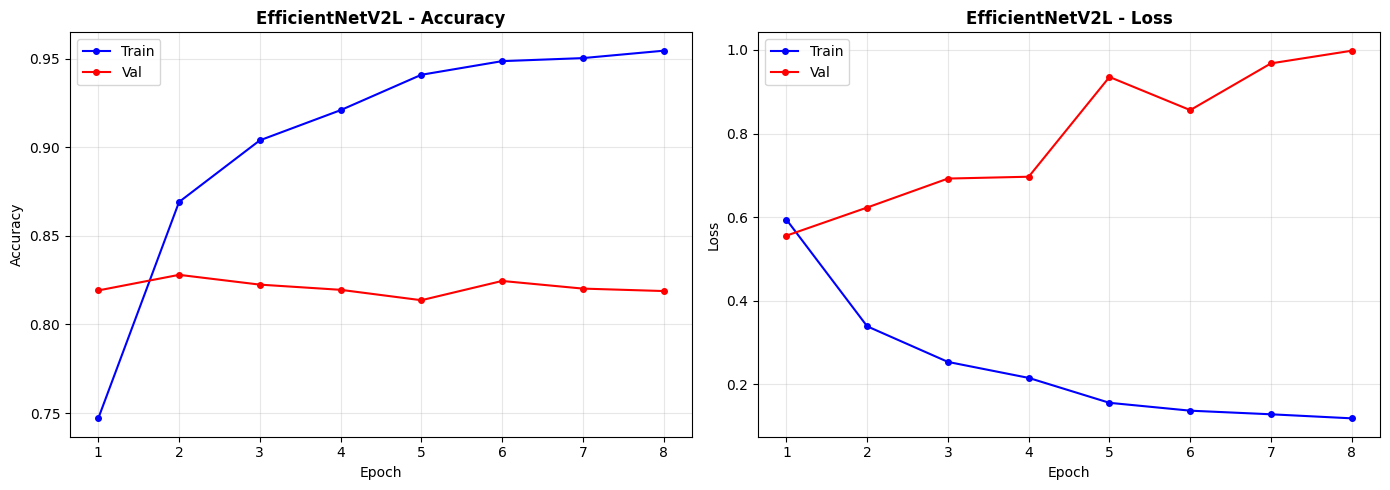

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetV2L_curves.png

346/346 ━━━━━━━━━━━━━━━━━━━━ 183s 504ms/step
   Manual acc (y_pred vs y_true): 0.8178
   model.evaluate accuracy      : 0.8178
   OK: accuracies match - reports below are trustworthy.


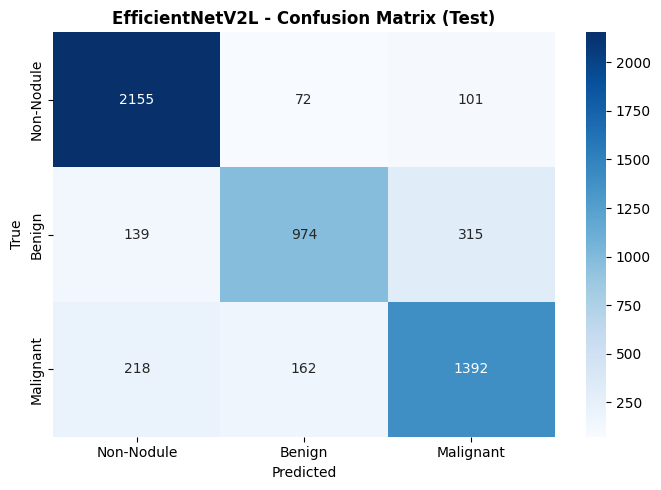

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetV2L_confusion.png

Classification Report (Test):
              precision    recall  f1-score   support

  Non-Nodule     0.8579    0.9257    0.8905      2328
      Benign     0.8063    0.6821    0.7390      1428
   Malignant     0.7699    0.7856    0.7777      1772

    accuracy                         0.8178      5528
   macro avg     0.8114    0.7978    0.8024      5528
weighted avg     0.8164    0.8178    0.8152      5528


Extracting features from 'feature_extractor' layer...
   Embedding dimension: 1280


Train EfficientNetV2L:   0%|          | 0/2250 [00:00<?, ?it/s]

ResourceExhaustedError: Exception encountered when calling Conv2D.call().

[1m{{function_node __wrapped__Conv2D_device_/job:localhost/replica:0/task:0/device:GPU:0}} OOM when allocating tensor with shape[16,10,10,3840] and type float on /job:localhost/replica:0/task:0/device:GPU:0 by allocator GPU_0_bfc [Op:Conv2D][0m

Arguments received by Conv2D.call():
  • inputs=tf.Tensor(shape=(16, 10, 10, 640), dtype=float32)

In [ ]:
# =============================================
# CELL 11: MAIN LOOP - ONE BACKBONE PER RUN
# =============================================
# Change CURRENT_ARCH and re-run only this cell to train the next backbone.
# Already-trained backbones are skipped automatically.

# CURRENT_ARCH = 'ResNet50V2'
# CURRENT_ARCH = 'DenseNet201'
# CURRENT_ARCH = 'EfficientNetB3'
CURRENT_ARCH = 'EfficientNetV2L'

results_path = os.path.join(OUTPUT_DIR, 'all_results.json')
if os.path.exists(results_path):
    with open(results_path) as f:
        all_results = json.load(f)
    print(f"Existing results: {list(all_results.keys())}")
else:
    all_results = {}
    print("New results file.")

if CURRENT_ARCH in all_results:
    acc = all_results[CURRENT_ARCH]['test_accuracy']*100
    print(f"{CURRENT_ARCH} already trained (acc={acc:.2f}%) - skipping.")
else:
    cfg = BACKBONE_CFG[CURRENT_ARCH]
    print("\n" + "="*70)
    print(f"CBAM + {CURRENT_ARCH}  |  {cfg['img_size']}x{cfg['img_size']}  |  batch={cfg['batch_size']}")
    print("="*70)

    # --- Datasets ------------------------------------------------------------
    print("\nLoading datasets...")
    train_ds, n_train = build_dataset(TRAIN_CSV, cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=False)
    # Re-shuffle train ONLY at each epoch, on top of the already-mixed CSV.
    # Buffer of 1024 is plenty since the CSV is no longer class-sorted.
    train_ds = train_ds.shuffle(buffer_size=1024, seed=RANDOM_SEED,
                                reshuffle_each_iteration=True)
    train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

    # Val and test: deterministic single shuffle at load time (no per-epoch reshuffle).
    # shuffle=True here triggers df.sample() inside build_dataset; the tf.data
    # pipeline keeps the order fixed so predict() and label-iteration align.
    val_ds,   n_val   = build_dataset(VAL_CSV,   cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    test_ds,  n_test  = build_dataset(TEST_CSV,  cfg['img_size'], cfg['batch_size'],
                                      shuffle=True, cache=True)
    print(f"   Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

    # --- Sanity checks (catch bugs in 5 seconds before 48 min of training) ---
    for imgs, labs in train_ds.take(1):
        t = np.argmax(labs.numpy(), axis=1)
        unique_counts = dict(zip(*np.unique(t, return_counts=True)))
        print(f"   First train batch class distribution: {unique_counts}")
        assert len(unique_counts) >= 2, "Train batch contains only ONE class - shuffle is broken!"

    val_labels_pass1 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    val_labels_pass2 = np.concatenate([np.argmax(l.numpy(), axis=1)
                                       for _, l in val_ds.take(5)])
    assert np.array_equal(val_labels_pass1, val_labels_pass2), \
        "Val dataset is non-deterministic between passes - predict/labels misalignment!"
    print(f"   Val determinism check: OK ({len(val_labels_pass1)} labels match across two passes)")

    # --- Model ---------------------------------------------------------------
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED)
    print("\nBuilding model...")
    model, backbone = build_cbam_model(CURRENT_ARCH)

    # --- Training + CodeCarbon -----------------------------------------------
    tracker = OfflineEmissionsTracker(
        project_name=f"CBAM_{CURRENT_ARCH}_v2",
        output_dir=OUTPUT_DIR,
        output_file=f"{CURRENT_ARCH}_emissions.csv",
        country_iso_code="MAR",
        log_level="error",
    )
    tracker.start()
    t0 = time.time()

    print(f"\nFine-tuning ({MAX_EPOCHS} epochs max, EarlyStopping patience=6)...")
    history, ckpt_path = train_model(model, CURRENT_ARCH, train_ds, val_ds)

    # --- Test evaluation -----------------------------------------------------
    print(f"\nEvaluating on the Test Set...")
    test_results = model.evaluate(test_ds, verbose=1, return_dict=True)
    print(f"   Test metrics: {test_results}")

    duration_s   = time.time() - t0
    emissions_kg = tracker.stop()
    print(f"   Duration : {duration_s/60:.1f} min")
    print(f"   CO2eq    : {float(emissions_kg)*1000:.2f} g")

    # --- Predictions and consistency check -----------------------------------
    plot_training_curves(history, CURRENT_ARCH)

    print("\nCollecting predictions on test set...")
    y_pred_proba = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.concatenate([np.argmax(labs.numpy(), axis=1) for _, labs in test_ds])

    # CRITICAL sanity check: manual accuracy must match model.evaluate accuracy
    manual_acc = (y_pred == y_true).mean()
    print(f"   Manual acc (y_pred vs y_true): {manual_acc:.4f}")
    print(f"   model.evaluate accuracy      : {test_results['accuracy']:.4f}")
    if abs(manual_acc - test_results['accuracy']) > 0.01:
        print("   WARNING: accuracies disagree - data pipeline ordering bug!")
    else:
        print("   OK: accuracies match - reports below are trustworthy.")

    plot_confusion(y_true, y_pred, CURRENT_ARCH)

    print("\nClassification Report (Test):")
    report_str  = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
    report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                        output_dict=True)
    print(report_str)

    # --- Feature extraction --------------------------------------------------
    print(f"\nExtracting features from 'feature_extractor' layer...")
    feat_extractor = build_feature_extractor(model)
    print(f"   Embedding dimension: {feat_extractor.output_shape[-1]}")

    X_train, y_train = extract_features(feat_extractor, train_ds, n_train,
                                        cfg['batch_size'], f"Train {CURRENT_ARCH}")
    X_val,   y_val   = extract_features(feat_extractor, val_ds,   n_val,
                                        cfg['batch_size'], f"Val   {CURRENT_ARCH}")
    X_test,  y_test  = extract_features(feat_extractor, test_ds,  n_test,
                                        cfg['batch_size'], f"Test  {CURRENT_ARCH}")
    print(f"   Shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")

    # --- Save ---------------------------------------------------------------
    feat_dir = os.path.join(OUTPUT_DIR, CURRENT_ARCH)
    os.makedirs(feat_dir, exist_ok=True)
    np.save(os.path.join(feat_dir, 'X_train.npy'), X_train)
    np.save(os.path.join(feat_dir, 'y_train.npy'), y_train)
    np.save(os.path.join(feat_dir, 'X_val.npy'),   X_val)
    np.save(os.path.join(feat_dir, 'y_val.npy'),   y_val)
    np.save(os.path.join(feat_dir, 'X_test.npy'),  X_test)
    np.save(os.path.join(feat_dir, 'y_test.npy'),  y_test)
    print(f"   Features saved: {feat_dir}")

    model.save(os.path.join(MODELS_DIR, f"CBAM_{CURRENT_ARCH}_final.keras"))
    print(f"   Model saved   : CBAM_{CURRENT_ARCH}_final.keras")

    # --- Update results JSON -------------------------------------------------
    all_results[CURRENT_ARCH] = {
        'img_size'       : cfg['img_size'],
        'batch_size'     : cfg['batch_size'],
        'feature_dim'    : int(X_train.shape[1]),
        'epochs_trained' : len(history.history['loss']),
        'test_accuracy'  : float(test_results['accuracy']),
        'test_auc'       : float(test_results['auc']),
        'test_precision' : float(test_results['precision']),
        'test_recall'    : float(test_results['recall']),
        'test_loss'      : float(test_results['loss']),
        'macro_f1'       : float(report_dict['macro avg']['f1-score']),
        'weighted_f1'    : float(report_dict['weighted avg']['f1-score']),
        'per_class_f1'   : {CLASS_NAMES[i]: float(report_dict[CLASS_NAMES[i]]['f1-score'])
                            for i in range(NUM_CLASSES)},
        'carbon': {
            'duration_min': round(duration_s/60, 2),
            'co2_g'       : round(float(emissions_kg)*1000, 2),
            'energy_kwh'  : round(float(emissions_kg)/0.634, 4),
            'tracker'     : 'codecarbon_OfflineTracker_MAR',
        },
    }
    with open(results_path, 'w') as f:
        json.dump(all_results, f, indent=2)

    print("\n" + "="*70)
    print(f"{CURRENT_ARCH} - DONE")
    print(f"   Test Accuracy : {test_results['accuracy']*100:.2f}%")
    print(f"   Test AUC      : {test_results['auc']:.4f}")
    print(f"   Macro F1      : {report_dict['macro avg']['f1-score']:.4f}")
    print(f"   Test Loss     : {test_results['loss']:.4f}")
    print(f"   Duration      : {duration_s/60:.1f} min")
    print(f"   Backbones done: {list(all_results.keys())}")
    print("="*70)
    print("\nNext: change CURRENT_ARCH at top of this cell and re-run.")

In [ ]:
# =============================================
# RECOVERY: load V2-L from Drive, extract features at batch=4
# Run this in a FRESH session (after Runtime > Restart session).
# =============================================
import os, gc, time
import numpy as np
import tensorflow as tf
from tensorflow import keras

# Verify the local data is still there from before the restart
assert os.path.exists('/content/local_data'), \
    "Local data was wiped - re-run Cell 2B first."
print("Local data present.")

# Verify the model checkpoint is on Drive
ckpt = os.path.join(MODELS_DIR, 'CBAM_EfficientNetV2L_best.keras')
assert os.path.exists(ckpt), f"Missing checkpoint: {ckpt}"
print(f"Checkpoint found ({os.path.getsize(ckpt)/(1024*1024):.0f} MB).")

# --- Aggressive GPU memory cleanup before loading -------------------------
keras.backend.clear_session()
gc.collect()
print(f"\nGPU memory before load:")
gpu_info = tf.config.experimental.get_memory_info('GPU:0')
print(f"   Current: {gpu_info['current']/(1024**3):.2f} GB")
print(f"   Peak   : {gpu_info['peak']/(1024**3):.2f} GB")

# --- Load model -----------------------------------------------------------
CURRENT_ARCH = 'EfficientNetV2L'
cfg = BACKBONE_CFG[CURRENT_ARCH]

print(f"\nLoading {CURRENT_ARCH} from Drive...")
t0 = time.time()
model = keras.models.load_model(
    ckpt,
    custom_objects={'CBAM': CBAM,
                    'ChannelAttention': ChannelAttention,
                    'SpatialAttention': SpatialAttention},
    compile=False,   # don't restore optimizer (we only need inference)
)
print(f"Loaded in {time.time()-t0:.1f}s.")

# --- Datasets at small batch ---------------------------------------------
SMALL_BATCH = 4
print(f"\nBuilding datasets at batch={SMALL_BATCH} for safe extraction...")
train_ds, n_train = build_dataset(TRAIN_CSV, cfg['img_size'], SMALL_BATCH,
                                  shuffle=True, cache=False)
val_ds,   n_val   = build_dataset(VAL_CSV,   cfg['img_size'], SMALL_BATCH,
                                  shuffle=True, cache=False)
test_ds,  n_test  = build_dataset(TEST_CSV,  cfg['img_size'], SMALL_BATCH,
                                  shuffle=True, cache=False)
print(f"   Train: {n_train}  |  Val: {n_val}  |  Test: {n_test}")

# --- Build feature extractor ---------------------------------------------
feat_extractor = build_feature_extractor(model)
print(f"\n   Embedding dimension: {feat_extractor.output_shape[-1]}")

# --- Extract features ----------------------------------------------------
print(f"\nExtracting features (batch=4, expect ~25-40 min total)...")
t0 = time.time()
X_train, y_train = extract_features(feat_extractor, train_ds, n_train,
                                    SMALL_BATCH, f"Train {CURRENT_ARCH}")
X_val,   y_val   = extract_features(feat_extractor, val_ds,   n_val,
                                    SMALL_BATCH, f"Val   {CURRENT_ARCH}")
X_test,  y_test  = extract_features(feat_extractor, test_ds,  n_test,
                                    SMALL_BATCH, f"Test  {CURRENT_ARCH}")
print(f"\nTotal extraction time: {(time.time()-t0)/60:.1f} min")
print(f"Shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")

# --- Save features --------------------------------------------------------
feat_dir = os.path.join(OUTPUT_DIR, CURRENT_ARCH)
os.makedirs(feat_dir, exist_ok=True)
np.save(os.path.join(feat_dir, 'X_train.npy'), X_train)
np.save(os.path.join(feat_dir, 'y_train.npy'), y_train)
np.save(os.path.join(feat_dir, 'X_val.npy'),   X_val)
np.save(os.path.join(feat_dir, 'y_val.npy'),   y_val)
np.save(os.path.join(feat_dir, 'X_test.npy'),  X_test)
np.save(os.path.join(feat_dir, 'y_test.npy'),  y_test)
print(f"\nFeatures saved: {feat_dir}")

# --- Update all_results.json with V2-L metrics ---------------------------
import json
results_path = os.path.join(OUTPUT_DIR, 'all_results.json')
with open(results_path) as f:
    all_results = json.load(f)

all_results['EfficientNetV2L'] = {
    'img_size'       : 300,
    'batch_size'     : 16,
    'feature_dim'    : int(X_train.shape[1]),
    'epochs_trained' : 8,
    'test_accuracy'  : 0.8178,
    'test_auc'       : 0.9314,
    'test_precision' : 0.8218,
    'test_recall'    : 0.8142,
    'test_loss'      : 0.6352,
    'macro_f1'       : 0.8024,
    'weighted_f1'    : 0.8152,
    'per_class_f1'   : {
        'Non-Nodule': 0.8905,
        'Benign'    : 0.7390,
        'Malignant' : 0.7777,
    },
    'carbon': {
        'duration_min': 211.0,
        'co2_g'       : 282.06,
        'energy_kwh'  : round(282.06 / 1000 / 0.634, 4),
        'tracker'     : 'codecarbon_OfflineTracker_MAR',
    },
}
with open(results_path, 'w') as f:
    json.dump(all_results, f, indent=2)

print("\n" + "="*70)
print(f"EfficientNetV2L - RECOVERY DONE")
print(f"   Test Accuracy : 81.78%")
print(f"   Test AUC      : 0.9314")
print(f"   Macro F1      : 0.8024")
print(f"   All backbones : {list(all_results.keys())}")
print("="*70)

Local data present.
Checkpoint found (718 MB).

GPU memory before load:
   Current: 0.00 GB
   Peak   : 0.00 GB

Loading EfficientNetV2L from Drive...
Loaded in 12.8s.

Building datasets at batch=4 for safe extraction...
   Train: 36000  |  Val: 5796  |  Test: 5528

   Embedding dimension: 1280

Extracting features (batch=4, expect ~25-40 min total)...


Train EfficientNetV2L:   0%|          | 0/9000 [00:00<?, ?it/s]

Val   EfficientNetV2L:   0%|          | 0/1449 [00:00<?, ?it/s]

Test  EfficientNetV2L:   0%|          | 0/1382 [00:00<?, ?it/s]


Total extraction time: 266.8 min
Shapes: train=(36000, 1280), val=(5796, 1280), test=(5528, 1280)

Features saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/EfficientNetV2L

EfficientNetV2L - RECOVERY DONE
   Test Accuracy : 81.78%
   Test AUC      : 0.9314
   Macro F1      : 0.8024
   All backbones : ['ResNet50V2', 'DenseNet201', 'EfficientNetB3', 'EfficientNetV2L']


In [ ]:
# =============================================
# CELL 12: COMPARATIVE TABLE (run after all 4 backbones)
# =============================================
with open(results_path) as f:
    all_results = json.load(f)

print(f"Available backbones: {list(all_results.keys())}")

rows = []
for arch, r in all_results.items():
    rows.append({
        'Backbone'   : arch,
        'Img'        : f"{r['img_size']}^2",
        'Epochs'     : r['epochs_trained'],
        'Feat dim'   : r['feature_dim'],
        'Acc (%)'    : round(r['test_accuracy']*100, 2),
        'AUC'        : round(r['test_auc'], 4),
        'Macro F1'   : round(r['macro_f1'], 4),
        'Log Loss'   : round(r['test_loss'], 4),
        'Time (min)' : r['carbon']['duration_min'],
        'CO2 (g)'    : r['carbon']['co2_g'],
        'kWh'        : r['carbon']['energy_kwh'],
    })
df_comp = pd.DataFrame(rows).sort_values('Acc (%)', ascending=False)
print("\n" + "="*110)
print("CBAM-CNN COMPARISON - Test Set (patient-level split, training balanced at 12k/class)")
print("="*110)
print(df_comp.to_string(index=False))
print("="*110)
best = df_comp.iloc[0]
print(f"\nBest: {best['Backbone']} - Acc {best['Acc (%)']}% | AUC {best['AUC']} | F1 {best['Macro F1']}")

csv_out = os.path.join(OUTPUT_DIR, 'cnn_comparison_v2.csv')
df_comp.to_csv(csv_out, index=False)
print(f"\nSaved: {csv_out}")

Available backbones: ['ResNet50V2', 'DenseNet201', 'EfficientNetB3', 'EfficientNetV2L']

CBAM-CNN COMPARISON - Test Set (patient-level split, training balanced at 12k/class)
       Backbone   Img  Epochs  Feat dim  Acc (%)    AUC  Macro F1  Log Loss  Time (min)  CO2 (g)    kWh
    DenseNet201 224^2       9      1920    83.45 0.9421    0.8184    0.4681       51.53    68.07 0.1074
     ResNet50V2 224^2      11      2048    81.91 0.9280    0.7963    0.7484       40.53    53.79 0.0848
 EfficientNetB3 224^2       9      1536    81.80 0.9372    0.8022    0.5996       34.63    45.67 0.0720
EfficientNetV2L 300^2       8      1280    81.78 0.9314    0.8024    0.6352      211.00   282.06 0.4449

Best: DenseNet201 - Acc 83.45% | AUC 0.9421 | F1 0.8184

Saved: /content/drive/MyDrive/Journal_Work_2026/Features_v2/cnn_comparison_v2.csv
